# GRAM ablations: components, weights and neighbors

β 敏感性与 acquisition 消融已由主检测实验覆盖，本 notebook 不再展示。
核组件消融（No identity、No gradient、No margin）与固定均匀权重合并为数值表；
保留 k 敏感性与自适应核权重轨迹图，绘图样式继续对齐 `analysis/figures/runtime/detection_runtime.pdf`。

**指标与聚合**：AUPRC / Precision 均为从首个预算点到该 noise rate 最大预算的归一化梯形积分，
不是末个 checkpoint 指标。先平均每个配置实际可用 seeds，再对未展示参数及三类噪声等权平均。
表格按 20% / 40% 噪声率分别展示；每类图对 20% / 40% 噪声率等权平均，以六个数据集的 2×3 面板展示。表内原始数值保留在内存，显示四位小数。
消融表默认平均全部七个 β；可在下方 `TABLE_BETAS` 中指定 β 子集。
k 敏感性和权重轨迹继续平均全部七个 β；展示时再平均两种噪声率，阴影为噪声率与噪声类型组合的合并样本 SD。

**GRAM 对照来源**：分别直接执行 `detect_result_vis.ipynb` 与 `detect_result_vis_isolation.ipynb`
中产生结果 DataFrame 的数据单元格，不执行绘图，也不修改来源 notebook。
两行均读取原第一组 `noise_mean_first`：主 notebook 重新读取当前实验结果；isolation 使用其显式数值快照。
先保留各 β 的原始展示点，再按与消融项相同的 `TABLE_BETAS` 等权平均。
两个来源即使显示值相同也保持独立行，保留文件哈希和原始点以便核查。

GRAM 两个导入对照沿用各自原第一组的已选 k；四个消融项沿用数据集参考 k，**不重新选 k**。
因此表格展示绝对 AUPRC / Precision，不把导入对照当成相同 k 的配对差值。
图使用 12 × 7.5 英寸画布、顶部共享图例和 2×3 数据集面板；数据集名称放在各面板的 x 轴名称下方，不显示噪声率/预算行标题或样本数。
两排均显示 x 轴名称与刻度，x/y 轴标签为 17 pt，小于 20 pt 的数据集名；子图显示横纵网格线。
所有表格、中间数据和来源保留在 notebook 中；磁盘仅保留 k 敏感性与权重轨迹的两张合并 PDF，
输出至 `analysis/figures/ablation/grid/`。

显示规则：先保留各噪声率的原有计算/对齐，再对 20% 和 40% 噪声率等权平均；阴影为两种噪声率与三类噪声的合并样本 SD。核权重仅展示共同的绝对预算区间 0–20%，每个点均包含两种噪声率。


In [1]:
from pathlib import Path
from itertools import product
import json
import sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

DATASETS = ['cifar10', 'cifar100', 'atis', 'qnli', 'adult', 'letter']
NOISE_TYPES = ['symmetric', 'pairflip', 'instance']
RHOS = [0.2, 0.4]
SEEDS = [0, 1, 2]
TABLES = {}  # Full table data stays in notebook memory.

def find_project_root(start):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'config/methods.py').is_file() and (candidate / 'src/gram/policy.py').is_file():
            return candidate
    raise FileNotFoundError('Run this notebook from the project root or analysis/.')

ROOT = find_project_root(Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.utils.run_logging import completed_run_exists

RESULTS = ROOT / 'results/detection'
SNAPSHOT_UTC = datetime.now(timezone.utc).isoformat(timespec='seconds')
pd.set_option('display.max_colwidth', 65)
pd.set_option('display.max_rows', 60)

def record_table(frame, name):
    TABLES[name] = frame.copy()

display(Markdown(f'Data snapshot: **{SNAPSHOT_UTC}**.'))

Data snapshot: **2026-11-05T01:48:13+00:00**.

In [2]:
# Follow runtime typography and borders, with x/y grids and smaller axis labels.
RUNTIME_PLOT_STYLE = {
    'font.family': 'DejaVu Sans',
    'font.weight': 'medium',
    'mathtext.fontset': 'dejavusans',
    'font.size': 16,
    'axes.titlesize': 20,
    'axes.titleweight': 'medium',
    'axes.labelsize': 17,
    'axes.labelweight': 'medium',
    'axes.linewidth': 1.0,
    'axes.edgecolor': '#222222',
    'axes.spines.top': True,
    'axes.spines.right': True,
    'axes.grid': True,
    'axes.grid.axis': 'both',
    'axes.axisbelow': True,
    'grid.color': '#D9D9D9',
    'grid.linestyle': '-',
    'grid.linewidth': 0.6,
    'grid.alpha': 0.8,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.major.size': 3,
    'ytick.major.size': 3,
    'xtick.major.width': 0.9,
    'ytick.major.width': 0.9,
    'xtick.major.pad': 2,
    'ytick.major.pad': 2,
    'legend.fontsize': 15,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.framealpha': 1,
    'legend.facecolor': 'white',
    'legend.edgecolor': '#BBBBBB',
    'figure.titlesize': 14,
    'figure.titleweight': 'bold',
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
}
plt.rcParams.update(RUNTIME_PLOT_STYLE)


def style_axes(ax, grid=True):
    ax.set_axisbelow(True)
    ax.grid(False, axis='both')
    if grid:
        ax.grid(True, axis='both', which='major', color='#D9D9D9',
                linewidth=0.6, linestyle='-', alpha=0.8)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('#222222')
        spine.set_linewidth(1.0)


def figure_legend(fig, handles, labels, ncol):
    legend = fig.legend(
        handles, labels, ncol=ncol, loc='upper center', bbox_to_anchor=(0.5, 0.995),
        frameon=True, fancybox=False, framealpha=1,
        facecolor='white', edgecolor='#BBBBBB', fontsize=15,
        handlelength=1.7, handleheight=0.85, handletextpad=0.5,
        columnspacing=1.5, labelspacing=0.45, borderpad=0.35,
    )
    legend.get_frame().set_linewidth(0.8)
    return legend

DATASET_LABELS = {
    'cifar10': 'CIFAR-10', 'cifar100': 'CIFAR-100', 'atis': 'ATIS',
    'qnli': 'QNLI', 'adult': 'Adult', 'letter': 'Letter',
}
# Reference palette: ocean blue, seafoam green and coral pink; retain component hue roles.
COMPONENT_COLORS = {'margin': '#5878A6', 'gradient': '#A6D0C6', 'identity': '#F4A7AE'}
COMPONENT_MARKERS = {'margin': 'o', 'gradient': 's', 'identity': '^'}
DATASET_COLORS = {
    'cifar10': '#0072B2', 'cifar100': '#D55E00', 'atis': '#009E73',
    'qnli': '#CC79A7', 'adult': '#E69F00', 'letter': '#222222',
}
DATASET_MARKERS = {
    'cifar10': 'o', 'cifar100': 's', 'atis': '^',
    'qnli': 'D', 'adult': 'P', 'letter': 'X',
}
FIGURE_MANIFEST = []
FIGURE_DATA = {}

def finish_figure(fig, stem, data, caption, output_dir=None):
    output_dir = ROOT / 'analysis/figures/ablation' if output_dir is None else output_dir
    output_dir.mkdir(parents=True, exist_ok=True)
    path = output_dir / f'{stem}.pdf'
    fig.savefig(path, format='pdf', dpi=300, bbox_inches=None, pad_inches=0, facecolor='white')
    FIGURE_DATA[stem] = data.copy()
    FIGURE_MANIFEST.append({'figure': stem, 'data_rows': len(data), 'caption': caption})
    plt.show()
    plt.close(fig)
    return path

plt.rcParams['pdf.fonttype'] = 42

## Load and validate the retained grid
Read completed full-model and kernel/weight runs only; check configurations, budgets and shared training fingerprints.
The five-k full-model sweep is retained for k sensitivity and kernel-weight trajectories.


In [3]:
from config.methods import (GRAM_DATASET_NEIGHBORS, GRAM_GRID_NEIGHBORS,
                            gram_grid_variants, method_config as effective_method_config)
PROJECT_ROOT, RESULTS_ROOT = ROOT, RESULTS
GRID_OUTPUT_DIR = ROOT / 'analysis/figures/ablation/grid'
GRID_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_METHODS = []
REQUIRED_SEEDS = [0]
GRAM_BETAS = [0.0, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]
GRAM_COLOR = '#D55E00'
GRID_VARIANTS_BY_DATASET = {dataset: gram_grid_variants(acquisitions=("repair_iv",),
                                               reference_neighbors=GRAM_DATASET_NEIGHBORS[dataset])
                            for dataset in DATASETS}
EXPECTED_BUDGETS = {rho: np.array([0.001,0.005,0.01,0.025] +
                    [round(.05*i,12) for i in range(1,round(rho/.05)+1)]) for rho in RHOS}

In [4]:
# Read every complete seed for each expected per-dataset configuration.
# Exact directory depths exclude source_metadata and shared training artifacts.
REQUIRED_FILES = ("run_args.json", "config.json", "metrics.csv", "queries.csv",
                  "predictions.csv", "summary.json")
REQUIRED_COLUMNS = ["configured_budget_fraction", "verification_fraction",
                    "unverified_auprc", "query_precision"]
RUN_KEYS = ["dataset", "noise_type", "rho", "setting", "seed"]
run_rows, all_checkpoint_frames = [], []
expected_configs = {
    variant: json.loads(json.dumps(effective_method_config("ours", variant)))
    for variants in GRID_VARIANTS_BY_DATASET.values() for variant in variants
}
expected_runs = []

run_specs, excluded_seed_dirs = [], []
for dataset in DATASETS:
    candidates = [("ours", variant) for variant in GRID_VARIANTS_BY_DATASET[dataset]]
    candidates += [(method, "") for method in BASELINE_METHODS]
    for (method, variant), noise_type, rho in product(candidates, NOISE_TYPES, RHOS):
        base = RESULTS_ROOT / dataset / noise_type / f"rho{rho:g}" / method
        if method == "ours":
            base /= variant
        available = []
        for directory in sorted(base.glob("seed*")):
            suffix = directory.name.removeprefix("seed")
            if not directory.is_dir() or not suffix.isdigit():
                continue
            seed = int(suffix)
            if completed_run_exists(directory, protocol="full_pool_detection", required_files=REQUIRED_FILES):
                available.append(seed)
                run_specs.append((dataset, method, variant, noise_type, rho, seed, directory))
            else:
                excluded_seed_dirs.append({"source": directory.relative_to(PROJECT_ROOT).as_posix(),
                                           "status": "incomplete seed excluded"})
        if not set(REQUIRED_SEEDS) <= set(available):
            raise ValueError(f"Required completed seed is missing: {base}; observed={available}")

for dataset, method, variant, noise_type, rho, seed, directory in run_specs:
    is_gram = method == "ours"
    if not completed_run_exists(directory, protocol="full_pool_detection", required_files=REQUIRED_FILES):
        raise ValueError(f"Missing/incomplete plotting run: {directory}")
    metrics_path = directory / "metrics.csv"
    config = json.loads((directory / "config.json").read_text())
    summary = json.loads((directory / "summary.json").read_text())
    identity = dict(dataset=dataset, noise_type=noise_type, rho=rho, method=method, seed=seed)
    if any(summary.get(key) != value for key, value in identity.items()):
        raise ValueError(f"Summary identity mismatch: {directory}")
    if (config.get("dataset") != dataset or config.get("method") != method
        or config.get("protocol") != "full_pool_detection"
        or summary.get("protocol") != "full_pool_detection"
        or any(config["scenario"].get(k) != identity[k] for k in ("noise_type", "rho", "seed"))):
        raise ValueError(f"Configuration identity mismatch: {directory}")
    mconfig = config["method_config"]
    if is_gram and (config.get("gram_variant") != variant
                    or summary.get("gram_variant") != variant
                    or mconfig != expected_configs[variant]):
        raise ValueError(f"GRAM effective configuration mismatch: {directory}")
    frame = pd.read_csv(metrics_path).sort_values("configured_budget_fraction")
    expected = EXPECTED_BUDGETS[rho]
    configured = frame["configured_budget_fraction"].to_numpy(float)
    if (len(configured) != len(expected) or not np.allclose(configured, expected)
        or not np.allclose(configured, summary["budgets"])
        or not np.allclose(configured, config["scenario"]["budgets"])):
        raise ValueError(f"Missing/unexpected budget checkpoints: {metrics_path}")
    values = frame[REQUIRED_COLUMNS].to_numpy(float)
    if not np.isfinite(values).all() or not ((values >= 0) & (values <= 1)).all():
        raise ValueError(f"Nonfinite/out-of-range metrics: {metrics_path}")
    counts = frame["verification_budget"].to_numpy(int)
    if (not np.all(np.diff(counts) > 0)
        or counts[-1] != summary["actual_budget"]
        or counts.tolist() != config["budget_checkpoint_target_counts"]):
        raise ValueError(f"Actual query budget mismatch: {metrics_path}")
    x = counts / summary["sample_count"]
    if not np.allclose(x, frame["verification_fraction"], atol=1e-5):
        raise ValueError(f"Verification fractions do not match counts: {metrics_path}")
    precision = frame["queried_mislabels_found"].to_numpy(int) / counts
    if not np.allclose(precision, frame["query_precision"], atol=1e-5):
        raise ValueError(f"Query precision does not match counts: {metrics_path}")
    frame["verification_fraction"] = x
    frame["query_precision"] = precision
    y = frame[["unverified_auprc", "query_precision"]].to_numpy(float)
    budget_means = np.trapz(y, x=x, axis=0) / (x[-1] - x[0])
    fingerprint = summary.get("shared_training_artifact_fingerprint")
    if is_gram and (not fingerprint or fingerprint != config["training_protocol"].get("shared_training_artifact_fingerprint")):
        raise ValueError(f"Missing/mismatched training fingerprint: {directory}")
    context = json.dumps({
        "dataset_config": config["dataset_config"], "model_config": config["model_config"],
        "sample_count": summary["sample_count"], "errors": summary["injected_mislabel_count"],
        "budgets": configured.tolist(), "query_counts": counts.tolist(),
        "fingerprint": fingerprint,
    }, sort_keys=True)
    setting = f"ours/{variant}" if is_gram else method
    record = {
        **identity, "setting": setting, "gram_variant": variant,
        "auprc": budget_means[0], "precision": budget_means[1],
        "budget_start": x[0], "budget_end": x[-1],
        "max_budget_configured": rho, "checkpoint_count": len(frame),
        "reference_k": GRAM_DATASET_NEIGHBORS[dataset] if is_gram else np.nan,
        "graph_neighbors": mconfig.get("graph_neighbors", np.nan),
        "acquisition": mconfig.get("acquisition", ""),
        "iv_beta": mconfig.get("iv_beta", np.nan),
        "kernel_components": "+".join(mconfig.get("active_kernel_components", [])),
        "kernel_weights": mconfig.get("kernel_weights", ""),
        "training_fingerprint": fingerprint, "pairing_context": context,
        "historical_result_reused": (directory / "result_reuse.json").is_file(),
        "training_fingerprint_overridden": "fingerprint_override" in summary,
        "source": metrics_path.relative_to(PROJECT_ROOT).as_posix(),
    }
    run_rows.append(record)
    expected_runs.append(tuple(record[key] for key in RUN_KEYS))
    checkpoints = frame[["checkpoint", "configured_budget_fraction", "verification_fraction",
                         "unverified_auprc", "query_precision"]].rename(
        columns={"unverified_auprc": "auprc", "query_precision": "precision"})
    for name, value in record.items():
        if name not in ("auprc", "precision"):
            checkpoints[name] = value
    if is_gram:
        checkpoints["beta"] = mconfig["iv_beta"]
        all_checkpoint_frames.append(checkpoints)

run_summaries = pd.DataFrame(run_rows)
observed_runs = pd.MultiIndex.from_frame(run_summaries[RUN_KEYS])
expected_index = pd.MultiIndex.from_tuples(expected_runs, names=RUN_KEYS)
if observed_runs.has_duplicates or not expected_index.equals(observed_runs):
    raise ValueError("Duplicate or incomplete comparison grid")
SEEDS = sorted(run_summaries.seed.unique().tolist())
assert len(run_summaries) == len(run_specs)
grid_checkpoints = pd.concat(all_checkpoint_frames, ignore_index=True)
grid_runs = run_summaries[run_summaries.method.eq("ours")].copy()
pair_keys = ["dataset", "noise_type", "rho", "seed"]
if not grid_runs.groupby(pair_keys)["pairing_context"].nunique().eq(1).all():
    raise ValueError("GRAM controls are not paired on training/noise/budget context")
seed_coverage = (run_summaries.groupby(["dataset", "noise_type", "rho", "method", "gram_variant", "setting"],
                                     as_index=False, dropna=False)
                 .agg(seed_count=("seed", "nunique"), seeds=("seed", lambda x: ",".join(map(str, sorted(x.unique()))))))
grid_inventory = (grid_runs.groupby("dataset", as_index=False)
                  .agg(configurations=("gram_variant", "nunique"), completed_runs=("setting", "size"),
                       reference_k=("reference_k", "first")))
coverage_summary = (seed_coverage[seed_coverage.method.eq("ours")].groupby("dataset", as_index=False)
                    .agg(configuration_scenarios=("seed_count", "size"),
                         seed_count_min=("seed_count", "min"), seed_count_max=("seed_count", "max")))
grid_inventory = grid_inventory.merge(coverage_summary, on="dataset", validate="one_to_one")
expected_config_counts = {dataset: len(variants) for dataset, variants in GRID_VARIANTS_BY_DATASET.items()}
assert grid_inventory.configurations.eq(grid_inventory.dataset.map(expected_config_counts)).all()
assert grid_inventory.configuration_scenarios.eq(
    grid_inventory.configurations * len(NOISE_TYPES) * len(RHOS)).all()
assert grid_inventory.seed_count_min.ge(1).all()
# Context JSON is checked in memory; source paths and fingerprints remain in the notebook DataFrames.
print(f"Loaded {len(grid_runs):,} GRAM grid runs and {len(run_summaries)-len(grid_runs):,} baseline runs; available seeds={SEEDS}.")
print("Each configuration averages all its completed seeds before configuration/checkpoint selection.")
display(grid_inventory)

Loaded 2,916 GRAM grid runs and 0 baseline runs; available seeds=[0, 1, 2].
Each configuration averages all its completed seeds before configuration/checkpoint selection.


,dataset,configurations,completed_runs,reference_k,configuration_scenarios,seed_count_min,seed_count_max
0,adult,63,486,10,378,1,3
1,atis,63,486,250,378,1,3
2,cifar10,63,486,25,378,1,3
3,cifar100,63,486,100,378,1,3
4,letter,63,486,250,378,1,3
5,qnli,63,486,10,378,1,3


## Marginal averages for the retained controls
Average available seeds within each configuration before averaging β and noise types. Each noise type has equal weight.
Kernel/weight controls stay at each dataset's reference k; neighbor controls retain all five k values.


In [5]:
# Build logical comparisons before averaging nuisance parameters.
FAMILY_SETTINGS = {
    "Neighbors": [(str(k), "adaptive", "repair_iv") for k in GRAM_GRID_NEIGHBORS],
    "Components": [("Fixed uniform", "fixed_uniform_weights", "repair_iv"),
                   ("No identity", "no_identity", "repair_iv"),
                   ("No gradient", "no_gradient", "repair_iv"),
                   ("No margin", "no_margin", "repair_iv")],

}
METRIC_LABELS = {"auprc": "Unverified AUPRC", "precision": "Verified Precision"}
grid_lookup = grid_runs.set_index(["dataset", "noise_type", "rho", "gram_variant", "seed"]).sort_index()
family_records = []
join_sources = lambda frame: " | ".join(sorted(frame.source))
for dataset, noise, rho, beta in product(DATASETS, NOISE_TYPES, RHOS, GRAM_BETAS):
    reference_k = GRAM_DATASET_NEIGHBORS[dataset]
    for family, settings in FAMILY_SETTINGS.items():
        for label, kernel, acquisition in settings:
            ks = [int(label) if family == "Neighbors" else reference_k]
            for k in ks:
                full_variant, = gram_grid_variants(betas=[beta], neighbors=[k], kernels=["adaptive"],
                                                 acquisitions=["repair_iv"], reference_neighbors=reference_k)
                variant, = gram_grid_variants(betas=[beta], neighbors=[k], kernels=[kernel],
                                             acquisitions=[acquisition], reference_neighbors=reference_k)
                rows = grid_lookup.loc[(dataset, noise, rho, variant)].sort_index()
                reference = grid_lookup.loc[(dataset, noise, rho, full_variant)].sort_index()
                common = rows.index.intersection(reference.index).sort_values()
                if len(common) == 0:
                    raise ValueError(f"No paired seeds: {dataset}, {noise}, {rho}, {variant}")
                paired, paired_reference = rows.loc[common], reference.loc[common]
                if not np.array_equal(paired.pairing_context.to_numpy(), paired_reference.pairing_context.to_numpy()):
                    raise ValueError(f"Unpaired grid comparison: {variant}")
                family_records.append({
                    "dataset": dataset, "noise_type": noise, "rho": rho, "beta": beta,
                    "family": family, "control": label, "graph_neighbors": k, "reference_k": reference_k,
                    "gram_variant": variant, "reference_variant": full_variant,
                    "auprc": rows.auprc.mean(), "precision": rows.precision.mean(),
                    "delta_auprc": (paired.auprc-paired_reference.auprc).mean(),
                    "delta_precision": (paired.precision-paired_reference.precision).mean(),
                    "control_seed_count": len(rows), "paired_seed_count": len(common),
                    "control_seeds": ",".join(map(str, rows.index)), "paired_seeds": ",".join(map(str, common)),
                    "source": join_sources(rows), "reference_source": join_sources(reference),
                    "paired_sources": join_sources(paired), "paired_reference_sources": join_sources(paired_reference),
                })
grid_family_runs = pd.DataFrame(family_records)
represented_sources = {path for value in grid_family_runs.source for path in value.split(" | ")}
assert represented_sources == set(grid_runs.source)
assert not grid_family_runs.duplicated(["dataset", "noise_type", "rho", "beta", "family", "control", "graph_neighbors"]).any()

SCORES = ["auprc", "precision", "delta_auprc", "delta_precision"]

def marginal_summary(family, control):
    """Each available seed -> equal nuisance settings -> equal noise types."""
    rows = grid_family_runs[grid_family_runs.family.eq(family)]
    keys = ["dataset", "rho", control]
    per_noise = rows.groupby(keys + ["noise_type"], as_index=False, observed=True)[SCORES].mean()
    summary = per_noise.groupby(keys, observed=True)[SCORES].agg(["mean", "std"]).reset_index()
    summary.columns = ["_".join(x).rstrip("_") if isinstance(x, tuple) else x for x in summary.columns]
    counts = per_noise.groupby(keys, observed=True).size().rename("noise_count").reset_index()
    coverage = rows.groupby(keys, observed=True).agg(
        beta_count=("beta", "nunique"), k_count=("graph_neighbors", "nunique"),
        seed_count_min=("control_seed_count", "min"), seed_count_max=("control_seed_count", "max"),
        paired_seed_count_min=("paired_seed_count", "min"), paired_seed_count_max=("paired_seed_count", "max"),
    ).reset_index()
    summary = summary.merge(counts, on=keys, validate="one_to_one").merge(coverage, on=keys, validate="one_to_one")
    assert summary.noise_count.eq(len(NOISE_TYPES)).all()
    record_table(per_noise, f"{family.lower()}_marginal_per_noise")
    record_table(summary, f"{family.lower()}_marginal_summary")
    return summary

MARGINALS = {family: marginal_summary(family, "control")
             for family in FAMILY_SETTINGS}
for family in ["Neighbors", "Components"]:
    assert MARGINALS[family].beta_count.eq(len(GRAM_BETAS)).all()
assert MARGINALS["Components"].k_count.eq(1).all()
print(f"All {grid_runs.source.nunique():,} grid runs represented; paired comparisons and marginal coverage verified.")

All 2,916 grid runs represented; paired comparisons and marginal coverage verified.


In [6]:
GRID_PDF_PATHS = []


def finish_marginal_figure(fig, stem, data, caption):
    path = finish_figure(fig, stem, data, caption, output_dir=GRID_OUTPUT_DIR)
    GRID_PDF_PATHS.append(path)
    print(path.relative_to(Path.cwd()).as_posix())
    return path


def average_noise_rates(frame, keys, metrics):
    """Equal rho means; pooled sample SD across 2 rates x 3 noise types."""
    expected_rates = set(RHOS)
    assert not frame.duplicated(keys + ['rho']).any()
    rows = []
    for key, panel in frame.groupby(keys, sort=False, observed=True):
        if len(keys) == 1:
            key = (key,) if not isinstance(key, tuple) else key
        assert set(panel.rho) == expected_rates, (key, panel.rho.tolist())
        row = dict(zip(keys, key))
        for metric in metrics:
            means = panel[f'{metric}_mean'].to_numpy(float)
            stds = panel[f'{metric}_std'].to_numpy(float)
            mean = means.mean()
            # Each rho summarizes three equally weighted noise-type means.
            n = 3
            variance = ((n - 1) * np.square(stds).sum()
                        + n * np.square(means - mean).sum()) / (n * len(means) - 1)
            row[f'{metric}_mean'] = mean
            row[f'{metric}_std'] = np.sqrt(max(0., variance))
        row['noise_rate_count'] = len(panel)
        rows.append(row)
    return pd.DataFrame(rows)


def align_ablation_layout(fig, axes, legend):
    """Six dataset panels in reading order, with a shared top legend."""
    fig.canvas.draw()
    legend_box = legend.get_window_extent(fig.canvas.get_renderer()).transformed(
        fig.transFigure.inverted())
    panel_top = legend_box.y0 - 0.14 / fig.get_figheight()
    fig.subplots_adjust(left=0.075, right=0.985, top=panel_top, bottom=0.17,
                        wspace=0.32, hspace=0.42)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for index, (ax, dataset) in enumerate(zip(axes.flat, DATASETS)):
        panel_box = ax.get_position()
        xlabel_box = ax.xaxis.label.get_window_extent(renderer).transformed(
            fig.transFigure.inverted())
        fig.text((panel_box.x0 + panel_box.x1) / 2,
                 xlabel_box.y0 - 5 / 72 / fig.get_figheight(),
                 f"({chr(ord('a') + index)}) {DATASET_LABELS[dataset]}",
                 ha='center', va='top', fontsize=20, fontweight='medium')


def plot_marginal_neighbors():
    order = [str(k) for k in GRAM_GRID_NEIGHBORS]
    values = average_noise_rates(MARGINALS['Neighbors'], ['dataset', 'control'],
                                 ['auprc', 'precision'])
    fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), squeeze=False)
    for ax, dataset in zip(axes.flat, DATASETS):
        panel = values[values.dataset.eq(dataset)].set_index('control').reindex(order)
        x = np.arange(len(order))
        for metric, color, marker in [('auprc', '#0072B2', 'o'), ('precision', '#009E73', 's')]:
            mean = panel[f'{metric}_mean'].to_numpy(float)
            std = panel[f'{metric}_std'].to_numpy(float)
            ax.plot(x, mean, color=color, marker=marker, markersize=7,
                    linewidth=3.2, label=METRIC_LABELS[metric])
            ax.fill_between(x, np.clip(mean-std, 0, 1), np.clip(mean+std, 0, 1),
                            color=color, alpha=.11)
        style_axes(ax)
        ax.set_xticks(x, order)
        ax.tick_params(axis='x', labelbottom=True)
        ax.set_ylim(0, 1)
        ax.set_yticks([0, 0.5, 1])
        ax.set_ylabel('Score', fontsize=17, fontweight='medium', labelpad=2)
        ax.set_xlabel(r'Graph neighbors $k$', fontsize=17, fontweight='medium', labelpad=2)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    legend = figure_legend(fig, handles[::-1], labels[::-1], ncol=2)
    align_ablation_layout(fig, axes, legend)
    return finish_marginal_figure(fig, 'marginal_neighbors_noise20_40', values,
        'Six datasets in a 2x3 layout. Equal mean over 20% and 40% noise rates after '
        'the existing within-rate aggregation/alignment. Bands show pooled sample SD '
        'across two noise rates and three noise types, clipped to [0, 1].')


In [7]:
# Read the source notebooks' own result frames; execute data cells only.
from hashlib import sha256
from IPython.core.inputtransformer2 import TransformerManager
from IPython.utils.capture import capture_output

TABLE_BETAS = tuple(GRAM_BETAS)  # Same beta subset for imported GRAM rows and ablations.
BASELINE_MODE = "noise_mean_first"  # Original first group present in both sources.
NOTEBOOK_IMPORTS = []


def read_notebook_frame(relative_path, frame_name):
    path = PROJECT_ROOT / relative_path
    raw = path.read_bytes()
    notebook = json.loads(raw)
    namespace = {"__name__": "__ablation_source__", "__file__": str(path),
                 "get_ipython": get_ipython}
    transformer = TransformerManager()
    executed = []
    # Source plotting styles and display output stay local to the import.
    with plt.rc_context(), capture_output():
        for index, cell in enumerate(notebook["cells"]):
            if cell["cell_type"] != "code":
                continue
            source = "".join(cell["source"])
            if ".savefig(" in source or source.lstrip().startswith("def legend_handles("):
                break
            code = transformer.transform_cell(source)
            exec(compile(code, f"{relative_path}:cell{index}", "exec"), namespace)
            executed.append(index)
            if frame_name in namespace:
                frame = namespace[frame_name].copy()
                break
        else:
            raise KeyError(f"Missing {frame_name} in data cells of {relative_path}")
    if frame_name not in namespace:
        raise KeyError(f"Missing {frame_name} before plotting cells in {relative_path}")
    if path.read_bytes() != raw:
        raise RuntimeError(f"Source notebook changed during import: {relative_path}")
    NOTEBOOK_IMPORTS.append({"source_notebook": relative_path,
                             "sha256": sha256(raw).hexdigest(),
                             "frame": frame_name, "executed_cells": executed,
                             "rows": len(frame)})
    return frame


main_gram_points = read_notebook_frame("analysis/detect_result_vis.ipynb", "gram_mean_first")
isolation_points = read_notebook_frame("analysis/detect_result_vis_isolation.ipynb", "plot_points")
isolation_gram_points = isolation_points[
    isolation_points.method.eq("ours") & isolation_points.aggregation.eq(BASELINE_MODE)].copy()
source_frames = {
    "GRAM (detect_result_vis.ipynb)": main_gram_points,
    "GRAM (detect_result_vis_isolation.ipynb)": isolation_gram_points,
}
source_rows = []
for label, points in source_frames.items():
    assert points.aggregation.eq(BASELINE_MODE).all()
    assert len(points) == len(DATASETS) * len(RHOS) * len(GRAM_BETAS)
    assert not points.duplicated(["dataset", "rho", "beta"]).any()
    assert set(points.beta) == set(GRAM_BETAS)
    assert np.isfinite(points[["auprc", "precision"]].to_numpy()).all()
    source_rows.append(points.assign(control=label))
detection_reference_points = pd.concat(source_rows, ignore_index=True)
record_table(detection_reference_points, "detection_reference_points")
record_table(pd.DataFrame(NOTEBOOK_IMPORTS), "detection_notebook_imports")
display(pd.DataFrame(NOTEBOOK_IMPORTS)[["source_notebook", "frame", "rows", "executed_cells"]])


,source_notebook,frame,rows,executed_cells
0,analysis/detect_result_vis.ipynb,gram_mean_first,84,"[1, 2, 3]"
1,analysis/detect_result_vis_isolation.ipynb,plot_points,252,"[1, 3, 4]"


## Kernel component and weight ablations

每个噪声率一张表，将 No identity、No gradient、No margin 和 Fixed uniform 合并展示。
列为六个数据集各自的 AUPRC / Precision；指标越高越好，均为预算平均值（0–1）。
两行 GRAM 分别直接来自主检测 notebook 的当前计算结果与 isolation 的固定快照。
各行使用相同 β 子集等权平均；消融项保留参考 k，对照沿用来源 notebook 已选的 k。
来源差异保留，不合并、不覆盖，不显示与导入对照的配对差值。


In [8]:
assert TABLE_BETAS and set(TABLE_BETAS) <= set(GRAM_BETAS)
assert len(set(TABLE_BETAS)) == len(TABLE_BETAS)
ABLATION_ORDER = ["No identity", "No gradient", "No margin", "Fixed uniform"]
BASELINE_ORDER = list(source_frames)
TABLE_ROW_ORDER = BASELINE_ORDER + ABLATION_ORDER
TABLE_MANIFEST = []

# Source results already average seeds and noise; only average the selected betas here.
reference_means = (detection_reference_points[detection_reference_points.beta.isin(TABLE_BETAS)]
    .groupby(["dataset", "rho", "control"], as_index=False)[["auprc", "precision"]].mean())
# Preserve the existing ablation rule: available-seed means -> equal betas -> equal noise types.
component_rows = grid_family_runs[
    grid_family_runs.family.eq("Components") & grid_family_runs.beta.isin(TABLE_BETAS)]
component_per_noise = (component_rows.groupby(["dataset", "rho", "control", "noise_type"],
                                             as_index=False)[["auprc", "precision"]].mean())
component_means = (component_per_noise.groupby(["dataset", "rho", "control"],
                                              as_index=False)[["auprc", "precision"]].mean())
component_comparison = pd.concat([reference_means, component_means], ignore_index=True)
assert len(component_comparison) == len(DATASETS) * len(RHOS) * len(TABLE_ROW_ORDER)
assert not component_comparison.duplicated(["dataset", "rho", "control"]).any()
assert np.isfinite(component_comparison[["auprc", "precision"]].to_numpy()).all()
record_table(component_per_noise, "component_table_per_noise")
record_table(component_comparison, "component_and_weight_comparison")

comparison_tables = {}
for rho in RHOS:
    points = component_comparison[np.isclose(component_comparison.rho, rho)]
    long = points.melt(id_vars=["control", "dataset"], value_vars=["auprc", "precision"],
                       var_name="metric", value_name="value")
    table = long.pivot(index="control", columns=["dataset", "metric"], values="value")
    columns = pd.MultiIndex.from_product([DATASETS, ["auprc", "precision"]], names=["Dataset", "Metric"])
    table = table.reindex(index=TABLE_ROW_ORDER, columns=columns)
    assert table.notna().all().all() and table.shape == (6, 12)
    table.columns = pd.MultiIndex.from_tuples(
        [(DATASET_LABELS[dataset], "AUPRC ↑" if metric == "auprc" else "Precision ↑")
         for dataset, metric in table.columns], names=["Dataset", "Metric"])
    table.index.name = "Configuration / GRAM source"
    comparison_tables[rho] = table
    record_table(table, f"component_weight_table_rho{rho:g}")
    caption = (f"Kernel component and weight ablations | {rho:.0%} noise | "
               f"Equal mean over {len(TABLE_BETAS)} beta value(s)")
    styled = (table.style.format("{:.4f}").set_caption(caption)
        .set_table_styles([
            {"selector": "", "props": [("border-collapse", "collapse"),
                                         ("font-family", "DejaVu Sans, sans-serif"), ("font-size", "14px")]},
            {"selector": "caption", "props": [("text-align", "left"), ("font-size", "16px"),
                                                ("color", "#222222"), ("padding", "8px 0")]},
            {"selector": "th", "props": [("font-weight", "normal"), ("white-space", "nowrap"),
                                           ("padding", "6px 9px")]},
            {"selector": "thead", "props": [("border-top", "0.75pt solid #222222"),
                                              ("border-bottom", "0.75pt solid #222222")]},
            {"selector": "td", "props": [("text-align", "right"), ("padding", "6px 9px"),
                                           ("font-variant-numeric", "tabular-nums")]},
            {"selector": "th.row_heading", "props": [("text-align", "left")]},
            {"selector": "tbody tr:nth-child(2)", "props": [("border-bottom", "0.75pt solid #999999")]},
            {"selector": "tbody tr:last-child", "props": [("border-bottom", "0.75pt solid #222222")]},
        ])
        .set_properties(subset=pd.IndexSlice[BASELINE_ORDER, :], **{"background-color": "#F5F5F5"}))
    display(styled)
    TABLE_MANIFEST.append({"table": f"component_weight_rho{rho:g}", "rows": len(table),
                           "metric_columns": len(table.columns), "betas": TABLE_BETAS,
                           "sources": tuple(item["source_notebook"] for item in NOTEBOOK_IMPORTS)})


## Graph-neighbor sensitivity
One 2×3 figure: one panel per dataset, averaging the 20% and 40% noise rates equally.
k curves average all seven β values, available seeds and noise types; bands show pooled sample SD across noise rates and noise types.
A shared top legend and dataset captions below each panel identify the six panels; noise/budget headings and sample counts are omitted.
Both rows show x-axis labels and ticks, with x/y grids and 17 pt axis labels below the 20 pt dataset names.

显示规则：先保留各噪声率的原有计算/对齐，再对 20% 和 40% 噪声率等权平均；阴影为两种噪声率与三类噪声的合并样本 SD。核权重仅展示共同的绝对预算区间 0–20%，每个点均包含两种噪声率。


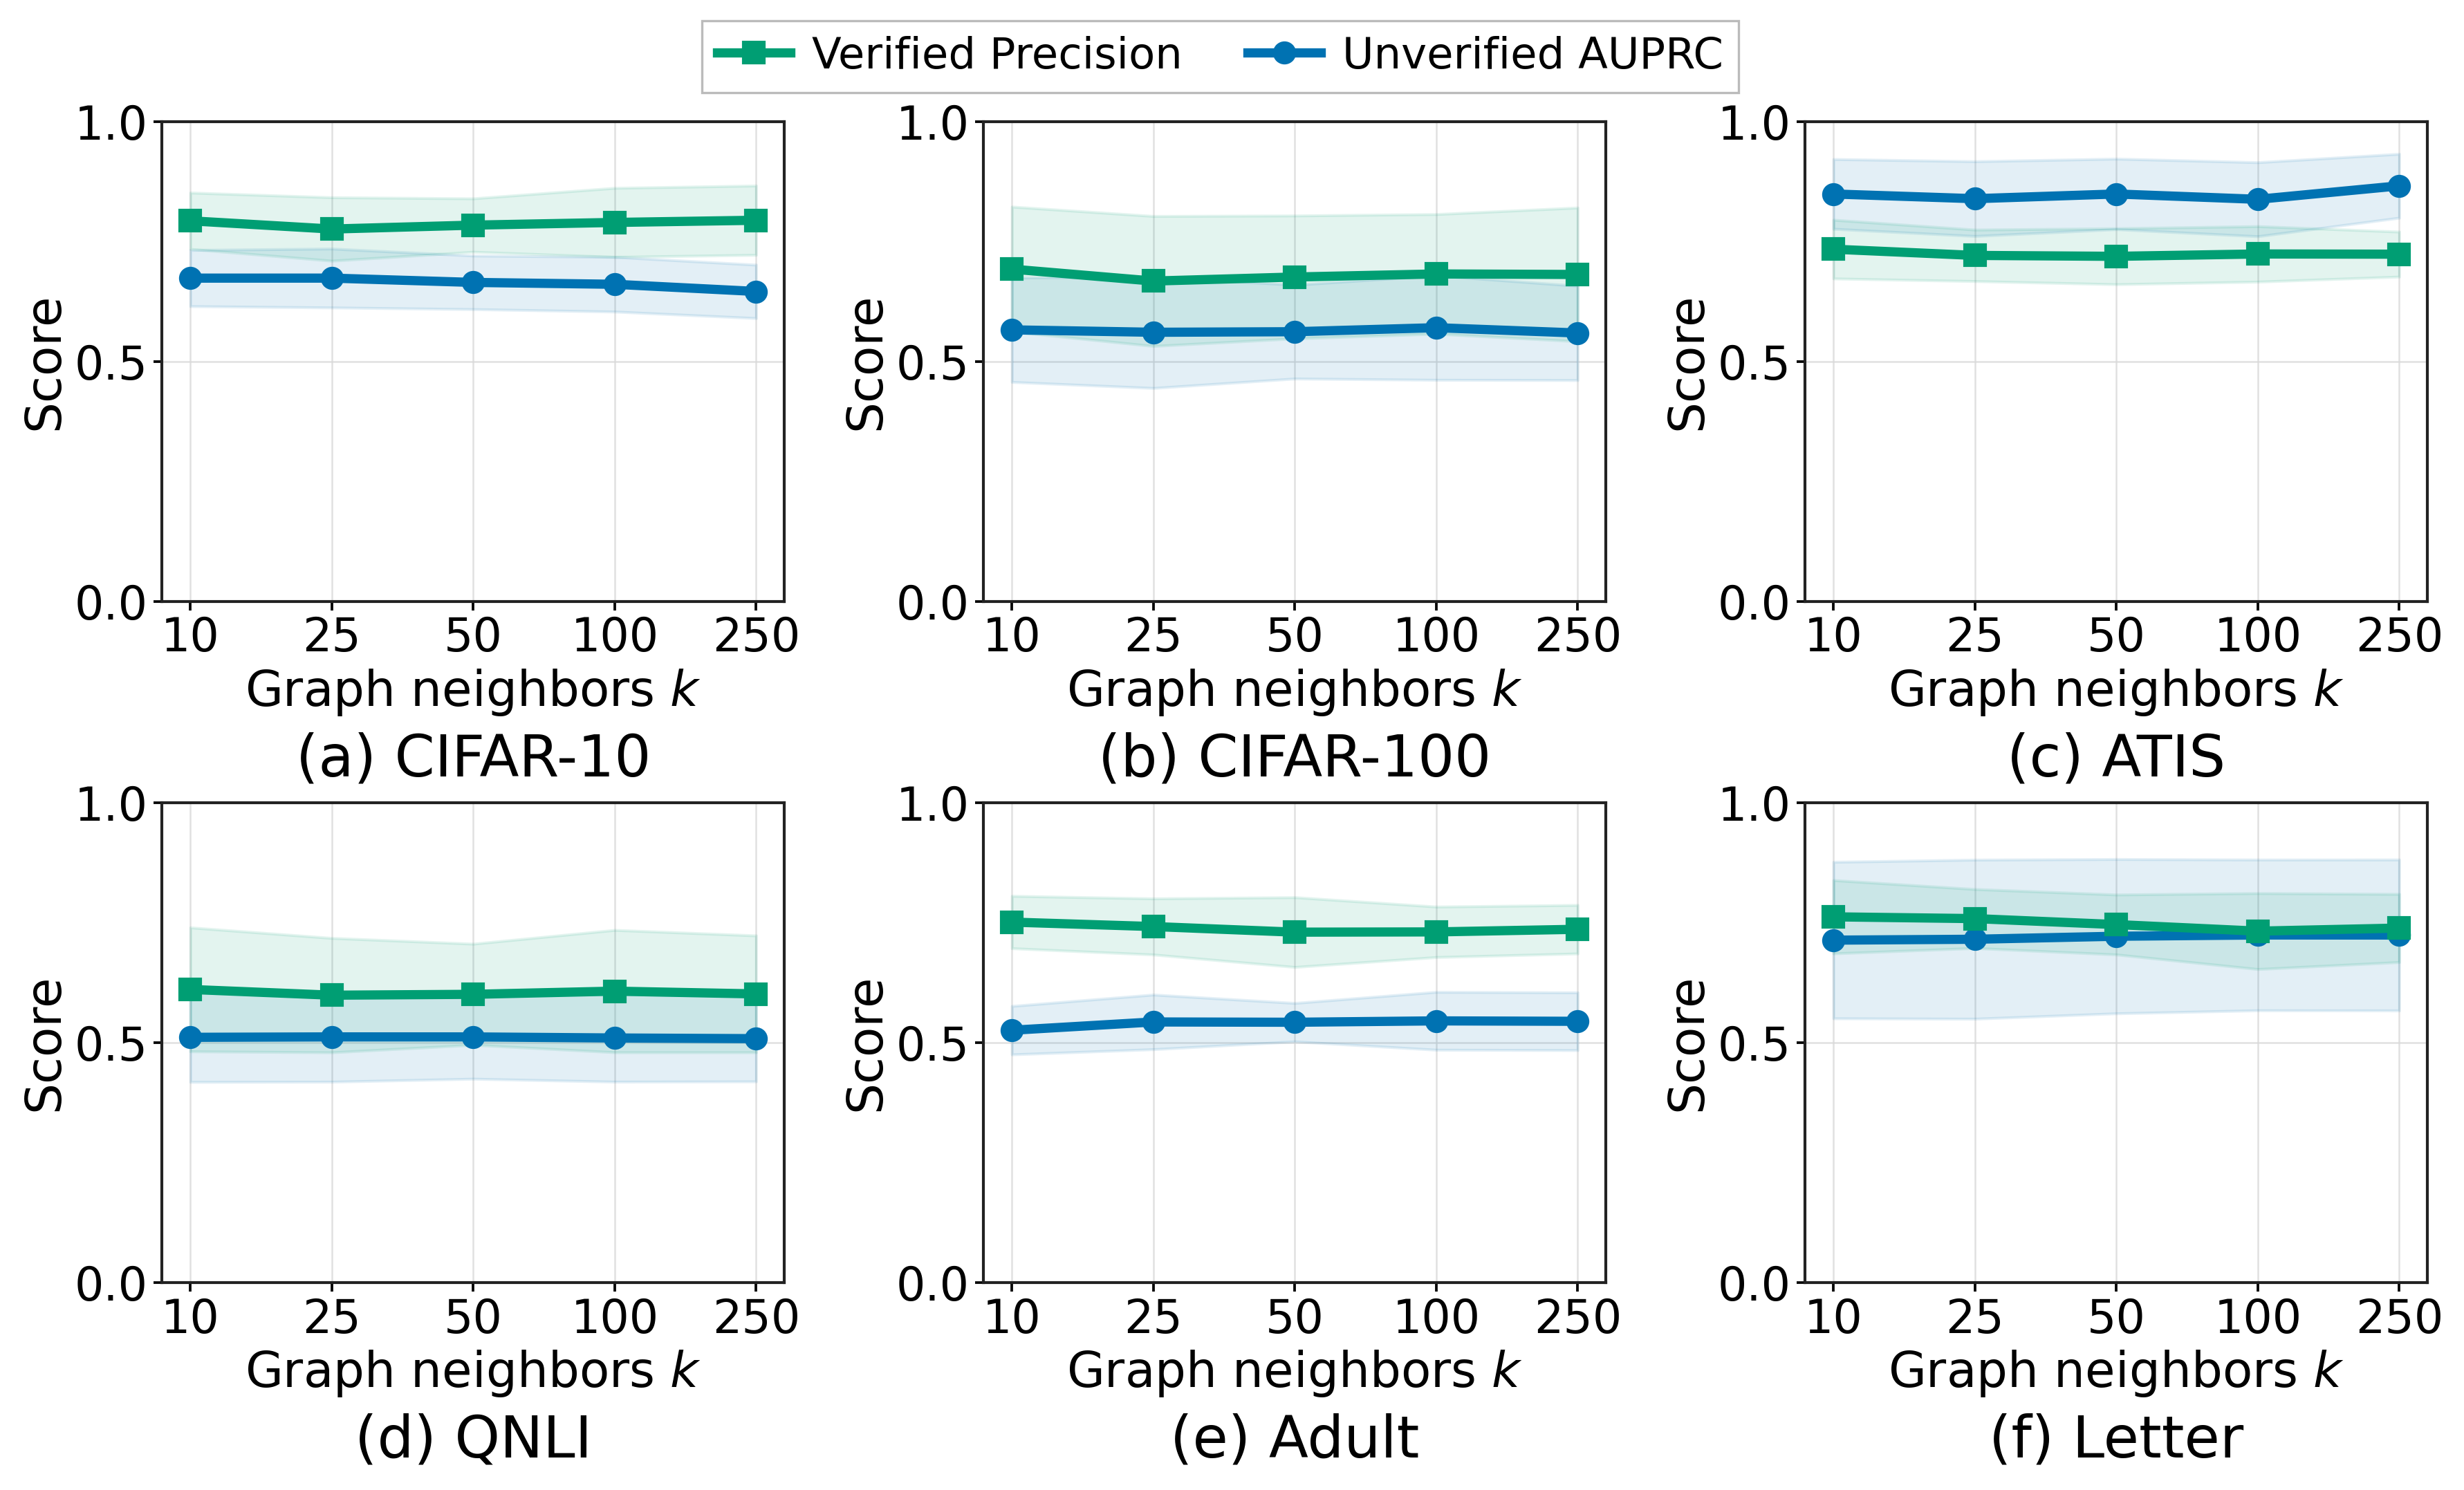

analysis/figures/ablation/grid/marginal_neighbors_noise20_40.pdf


PosixPath('/workspace/wupj/py-programs/GRAM/analysis/figures/ablation/grid/marginal_neighbors_noise20_40.pdf')

In [7]:
plot_marginal_neighbors()


## Adaptive kernel weights
One 2×3 figure: one panel per dataset, averaging the 20% and 40% noise rates equally.
Keep the verification-budget axis and average β, k, seeds and noise types.
All complete adaptive repair + IV runs in the parameter grid contribute.
Both rows show x-axis labels and ticks, with x/y grids and 17 pt axis labels below the 20 pt dataset names; sample counts are omitted.

显示规则：先保留各噪声率的原有计算/对齐，再对 20% 和 40% 噪声率等权平均；阴影为两种噪声率与三类噪声的合并样本 SD。核权重仅展示共同的绝对预算区间 0–20%，每个点均包含两种噪声率。


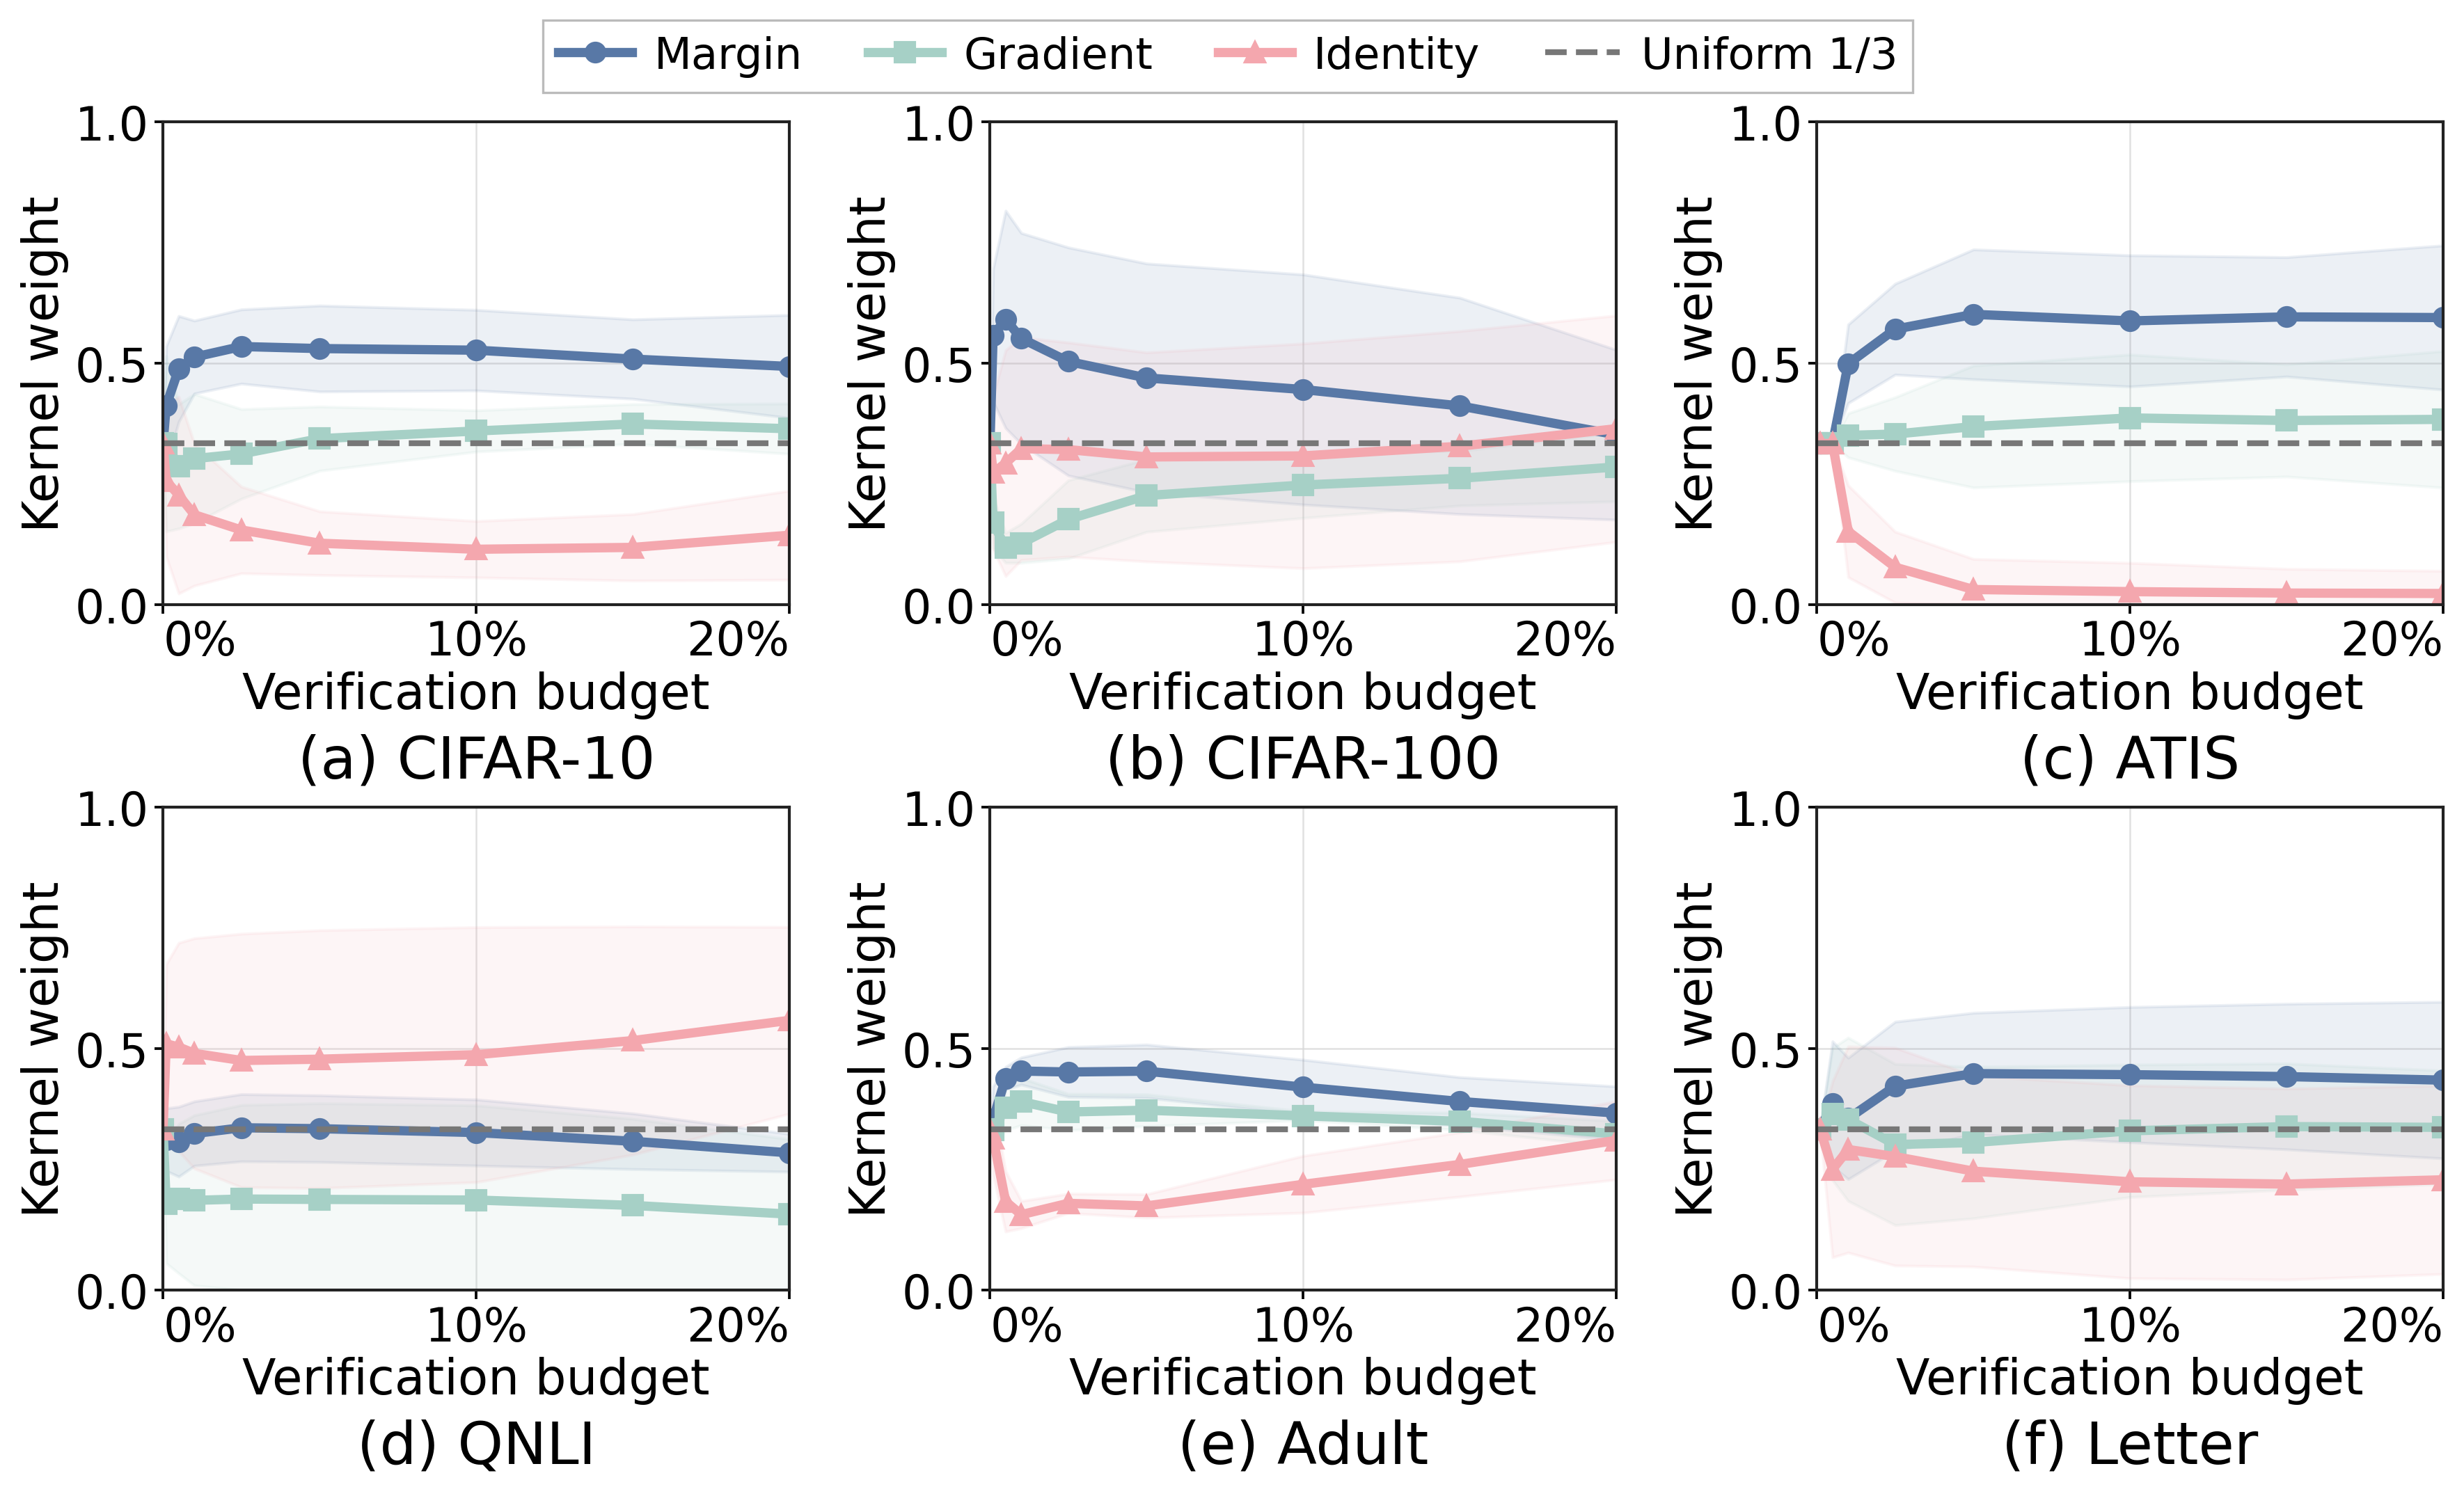

analysis/figures/ablation/grid/marginal_adaptive_kernel_weights_noise20_40.pdf


PosixPath('/workspace/wupj/py-programs/GRAM/analysis/figures/ablation/grid/marginal_adaptive_kernel_weights_noise20_40.pdf')

In [8]:
# Complete adaptive repair+IV grid only: average beta and k as nuisance variables.
# Resolve beta=0 aliases through the registry, then count each logical configuration once.
weight_specs = grid_family_runs[grid_family_runs.family.eq("Neighbors")][
    ["dataset", "noise_type", "rho", "beta", "graph_neighbors", "gram_variant"]].drop_duplicates()
weight_sources = grid_runs.merge(weight_specs, on=["dataset", "noise_type", "rho", "graph_neighbors", "gram_variant"],
                                validate="many_to_one")
weight_columns = ["omega_margin", "omega_gradient", "omega_identity"]
weight_frames = []
for run in weight_sources.itertuples(index=False):
    weight_path = PROJECT_ROOT / Path(run.source).parent / "kernel_weights.csv"
    if not weight_path.is_file():
        raise FileNotFoundError(f"Missing weight trajectory: {weight_path}")
    w = pd.read_csv(weight_path)
    x = w.configured_budget_fraction.to_numpy(float)
    if (not np.allclose(x, np.r_[0., EXPECTED_BUDGETS[run.rho]])
        or not np.isfinite(w[weight_columns]).all().all()
        or not w[weight_columns].ge(0).all().all()
        or not np.allclose(w[weight_columns].sum(axis=1), 1, atol=1e-6)):
        raise ValueError(f"Invalid weight trajectory: {weight_path}")
    for key in ["dataset", "noise_type", "rho", "seed", "beta", "graph_neighbors"]:
        w[key] = getattr(run, key)
    weight_frames.append(w)
weights = pd.concat(weight_frames, ignore_index=True)
weight_keys = ["dataset", "rho", "noise_type", "beta", "graph_neighbors", "configured_budget_fraction"]
weight_seed_means = weights.groupby(weight_keys, as_index=False, observed=True)[weight_columns].mean()
weight_per_noise = weight_seed_means.groupby(
    ["dataset", "rho", "noise_type", "configured_budget_fraction"], as_index=False, observed=True)[weight_columns].mean()
weight_summary = weight_per_noise.groupby(
    ["dataset", "rho", "configured_budget_fraction"], observed=True)[weight_columns].agg(["mean", "std", "count"])
assert (weight_summary.xs("count", axis=1, level=1) == len(NOISE_TYPES)).all().all()
assert np.allclose(weight_summary.xs("mean", axis=1, level=1).sum(axis=1), 1)
record_table(weight_sources, "adaptive_weight_sources")
record_table(weight_per_noise, "adaptive_weights_marginal_per_noise")
record_table(weight_summary.reset_index(), "adaptive_weights_marginal_summary")

def plot_marginal_weights():
    # Both rates contribute at every displayed budget: use their common 0--20% window.
    common_budget_end = min(RHOS)
    source = weight_summary.reset_index()
    source.columns = ['_'.join(column).rstrip('_') if isinstance(column, tuple) else column
                      for column in source.columns]
    source = source[source.configured_budget_fraction.le(common_budget_end + 1e-12)]
    components = ['margin', 'gradient', 'identity']
    values = average_noise_rates(source, ['dataset', 'configured_budget_fraction'],
                                 [f'omega_{component}' for component in components])
    fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), squeeze=False)
    for ax, dataset in zip(axes.flat, DATASETS):
        panel = values[values.dataset.eq(dataset)].sort_values('configured_budget_fraction')
        x = panel.configured_budget_fraction.to_numpy(float)
        for component in components:
            mean = panel[f'omega_{component}_mean'].to_numpy(float)
            std = panel[f'omega_{component}_std'].to_numpy(float)
            color, marker = COMPONENT_COLORS[component], COMPONENT_MARKERS[component]
            ax.plot(x, mean, color=color, marker=marker, markersize=6.5,
                    linewidth=3.2, label=component.capitalize())
            ax.fill_between(x, np.clip(mean-std, 0, 1), np.clip(mean+std, 0, 1),
                            color=color, alpha=.11)
        ax.axhline(1/3, color='#777777', linestyle='--', linewidth=2.0, label='Uniform 1/3')
        ax.set_xlim(0, common_budget_end)
        ax.set_xticks(np.linspace(0, common_budget_end, 3))
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.get_xticklabels()[0].set_horizontalalignment('left')
        ax.get_xticklabels()[-1].set_horizontalalignment('right')
        ax.set_ylim(0, 1)
        ax.set_yticks([0, 0.5, 1])
        style_axes(ax)
        ax.set_ylabel('Kernel weight', fontsize=17, fontweight='medium', labelpad=2)
        ax.set_xlabel('Verification budget', fontsize=17, fontweight='medium', labelpad=2)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    legend = figure_legend(fig, handles, labels, ncol=4)
    align_ablation_layout(fig, axes, legend)
    return finish_marginal_figure(fig, 'marginal_adaptive_kernel_weights_noise20_40', values,
        'Six datasets in a 2x3 layout. Equal mean over 20% and 40% noise rates at matching '
        'absolute budget fractions in their common 0--20% window, after within-rate beta/k/seed '
        'and noise-type averaging. Bands show pooled sample SD across both rates and three noise types.')


plot_marginal_weights()


In [11]:
display(pd.DataFrame(TABLE_MANIFEST))
display(pd.DataFrame(FIGURE_MANIFEST))
assert len(comparison_tables) == 2
assert len(GRID_PDF_PATHS) == 2
assert len(set(GRID_PDF_PATHS)) == len(GRID_PDF_PATHS)


,table,rows,metric_columns,betas,sources
0,component_weight_rho0.2,6,12,"(0.0, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0)","(analysis/detect_result_vis.ipynb, analysis/detect_result_vis..."
1,component_weight_rho0.4,6,12,"(0.0, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0)","(analysis/detect_result_vis.ipynb, analysis/detect_result_vis..."


,figure,data_rows,caption
0,marginal_neighbors_noise20_40,60,"Rows show 20% and 40% noise separately. Available seeds, then..."
1,marginal_adaptive_kernel_weights_noise20_40,396,Rows show 20% and 40% noise separately. Average available see...
